# Distance-based models: KNN and SVR

**Author:** Kiersten Cheatham

This notebook shows the results of two models that predict hourly bike rentals from weather and calendar features:

- **KNN (K-Nearest Neighbors)** predicts an hour by averaging the most similar past hours.
- **SVR (Support Vector Regression)** fits a smooth curve through the data, with the RBF kernel.

Each model was trained separately for **casual riders**, **registered riders** and **total rentals**. Then I checked whether adding the casual and registered predictions beats predicting the total directly.

**How the models were run.** The training code is in `src/distance_models.py` (`python -m src.distance_models knn` and `... svr`). This notebook only loads the saved results from `results/distance_models/`, so it runs in seconds.

**Method (same as the rest of the team):**
- Train on January 2011 to September 2012. Test on October to December 2012.
- Models learn `log1p(count)`, and predictions are converted back to rental counts.
- Settings were chosen with 5 expanding-window (time-ordered) cross-validation folds, using RMSE in rental counts. The test set was never used to choose settings.
- Features are scaled inside each fold so no information leaks from later hours.
- Metrics: RMSE (main), MAE and RMSLE.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Works whether the notebook is run from the project root or from results/.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
OUT = ROOT / "results" / "distance_models"
pd.options.display.float_format = "{:.3f}".format

knn = pd.read_csv(OUT / "knn_metrics.csv")
svr = pd.read_csv(OUT / "svr_metrics.csv")
mine = pd.concat([knn, svr], ignore_index=True)

## 1. Results on the test period (October to December 2012)

Lower is better for all three metrics. `summed_total` is the casual prediction plus the registered prediction.

In [2]:
cols = ["model", "target", "RMSE", "MAE", "RMSLE"]
mine[cols]

,model,target,RMSE,MAE,RMSLE
0,KNN,casual,25.867,13.189,0.663
1,KNN,registered,99.268,66.584,0.575
2,KNN,cnt,111.867,75.767,0.563
3,KNN,summed_total,112.183,76.066,0.558
4,SVR,casual,19.033,9.874,0.552
5,SVR,registered,56.822,34.058,0.413
6,SVR,cnt,63.030,38.822,0.397
7,SVR,summed_total,62.628,38.355,0.394


## 2. Which settings won, and were they inside the search range?

A best setting at the edge of the search range means the search should be widened. These are all inside the range.

In [3]:
best = mine[mine.target != "summed_total"].copy()
best["setting"] = best.apply(
    lambda r: f"k={int(r.n_neighbors)}, weights={r.weights}" if r.model == "KNN" else f"C={r.C:g}", axis=1)
best[["model", "target", "setting", "CV_RMSE", "RMSE"]].rename(columns={"CV_RMSE": "validation RMSE", "RMSE": "test RMSE"})

,model,target,setting,validation RMSE,test RMSE
0,KNN,casual,"k=5, weights=distance",29.512,25.867
1,KNN,registered,"k=2, weights=distance",91.437,99.268
2,KNN,cnt,"k=2, weights=distance",108.771,111.867
4,SVR,casual,C=1,28.199,19.033
5,SVR,registered,C=1,80.603,56.822
6,SVR,cnt,C=1,96.389,63.030


### Tuning curves

Each curve shows the average validation RMSE across the 5 time-ordered folds for every setting tried.

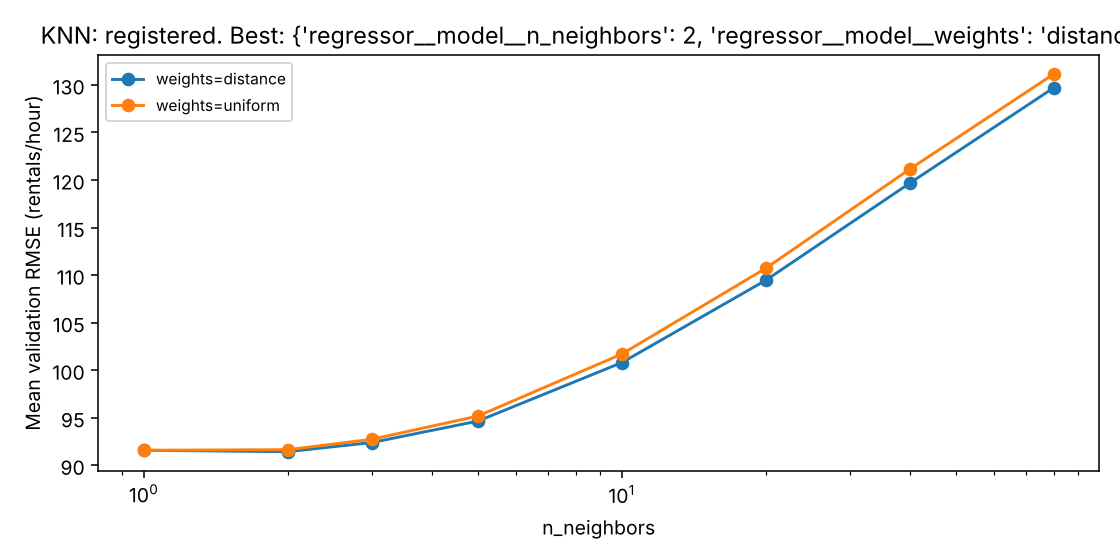

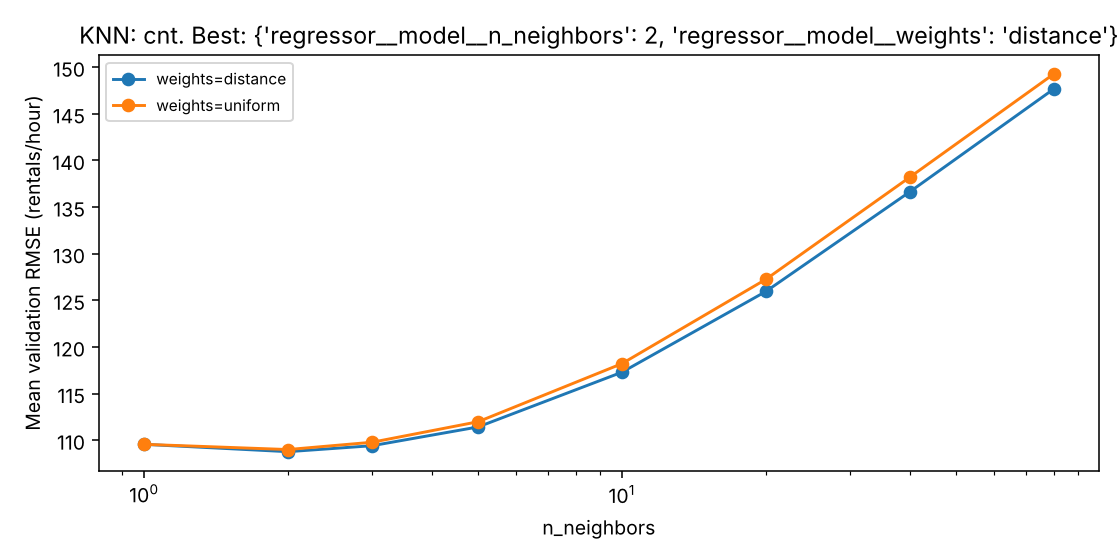

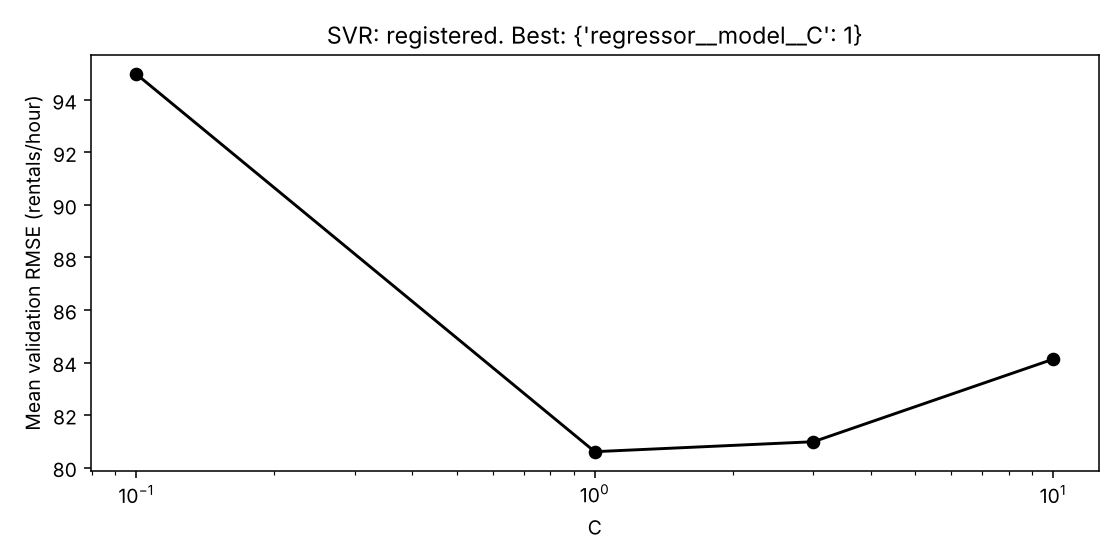

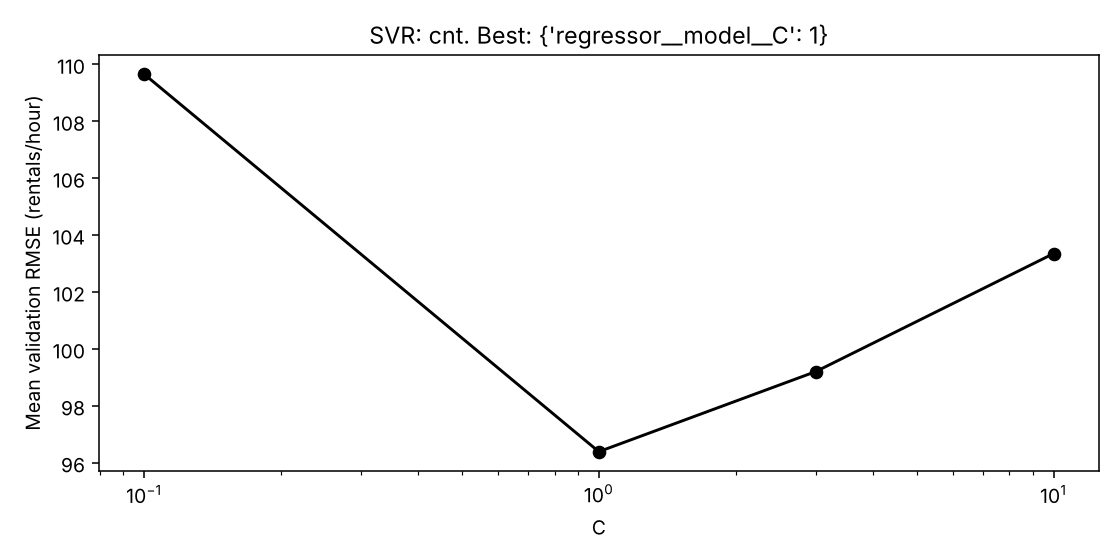

In [4]:
for name in ["knn_registered_tuning.png", "knn_cnt_tuning.png", "svr_registered_tuning.png", "svr_cnt_tuning.png"]:
    display(Image(filename=str(OUT / name), width=560))

**KNN tuning notes**
- *Tried:* `k` from 1 to 80, with uniform and distance weighting.
- *Result:* the best was `k=5` for casual riders and `k=2` for registered and total, always with distance weighting.
- *Decision:* the first search started at `k=3`, which was the best value for registered and total, so I widened it to include `k=1` and `k=2`. `k=2` improved validation RMSE only slightly (total: 109.4 to 108.8) and the test scores barely changed, so KNN is limited by the method, not by the settings.
- *Why:* hourly demand has sharp daily peaks. KNN copies the most similar past hours, and larger `k` blurs those peaks, so small `k` wins. It can't learn smooth trends beyond the hours it has seen.
- *Caution:* training error is near zero with distance weighting because each training hour counts as its own nearest neighbor, so only validation and test scores are meaningful.

**SVR tuning notes**
- *Tried:* `C` of 0.1, 1, 3 and 10, with the RBF kernel.
- *Result:* `C=1` won for all three targets. It is in the middle of the range, so the range did not need widening.
- *Decision:* I left out `C=100` because a single fit took several minutes. Since the best value was not near the top of the range, leaving it out did not hide a better setting.
- *Why:* SVR fits smooth curved patterns, such as demand rising and falling through the day, and large `C` values chase individual noisy hours, so a moderate `C` works best.

## 3. How do these models compare with the rest of the team?

Scores for the other models come from Malachi's shared evaluation (`results/evaluation/metrics.csv`), which uses the same test hours.

In [5]:
team = pd.read_csv(ROOT / "results" / "evaluation" / "metrics.csv")[["model", "target", "RMSE", "MAE", "RMSLE"]]
allm = pd.concat([team, mine[cols]], ignore_index=True)
table = allm.pivot(index="model", columns="target", values="RMSE")[["casual", "registered", "cnt", "summed_total"]]
table = table.sort_values("cnt")
table.columns = ["casual", "registered", "total (direct)", "total (summed)"]
table

,casual,registered,total (direct),total (summed)
model,,,,
SVR,19.033,56.822,63.030,62.628
Ridge,26.908,62.155,70.019,70.625
Lasso,27.889,62.719,74.255,72.845
Random Forest tuned,24.105,72.107,88.164,82.977
Random Forest baseline,24.105,72.107,88.164,82.977
Decision Tree baseline,35.292,89.743,95.497,98.120
Decision Tree tuned,27.743,81.908,99.979,91.451
KNN,25.867,99.268,111.867,112.183


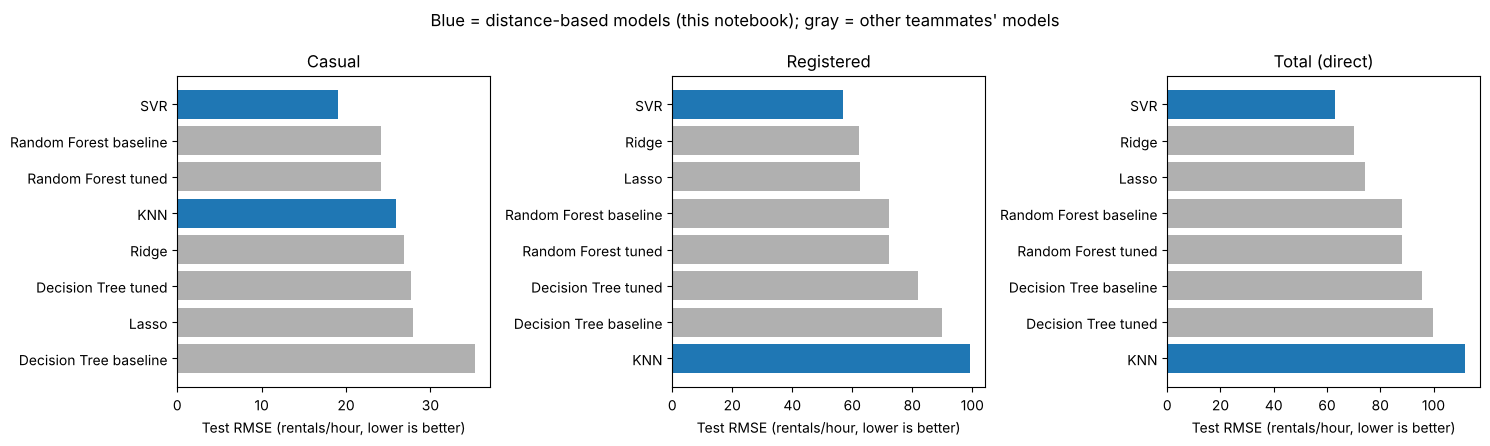

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=False)
for ax, target, title in zip(axes, ["casual", "registered", "cnt"], ["Casual", "Registered", "Total (direct)"]):
    data = allm[allm.target == target].sort_values("RMSE")
    colors = ["#1f77b4" if m in ("KNN", "SVR") else "#b0b0b0" for m in data.model]
    ax.barh(data.model, data.RMSE, color=colors)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Test RMSE (rentals/hour, lower is better)")
fig.suptitle("Blue = distance-based models (this notebook); gray = other teammates' models")
fig.tight_layout()
plt.show()

**Reading the comparison**
- SVR has the lowest test RMSE for casual, registered and total rentals among the saved models. KNN is the weakest of the models shown, except that its casual score is competitive.
- This is one test period (three months, one season), and the earlier feature choices also looked at this test period. So I treat the comparison as the team's fixed test set, not as a final proof that one model is best.
- The models also used different tuning ranges, so small gaps should not be over-read.

## 4. Does summing casual + registered beat predicting the total directly?

In [7]:
rows = []
for model in ["KNN", "SVR"]:
    d = mine[(mine.model == model) & (mine.target == "cnt")].iloc[0]
    s = mine[(mine.model == model) & (mine.target == "summed_total")].iloc[0]
    rows.append({"model": model, "direct RMSE": d.RMSE, "summed RMSE": s.RMSE,
                 "change from summing (%)": 100 * (d.RMSE - s.RMSE) / d.RMSE,
                 "direct MAE": d.MAE, "summed MAE": s.MAE})
pd.DataFrame(rows)

,model,direct RMSE,summed RMSE,change from summing (%),direct MAE,summed MAE
0,KNN,111.867,112.183,-0.282,75.767,76.066
1,SVR,63.030,62.628,0.638,38.822,38.355


Positive means summing helped. For SVR the improvement is about 0.6%, and for KNN summing is slightly worse. Both differences are small. With only one three-month test period, I would not call either a real win for the two-model approach.

## 5. Where does SVR make mistakes?

Residual = actual minus predicted, so a positive value means the model **under**-predicted.

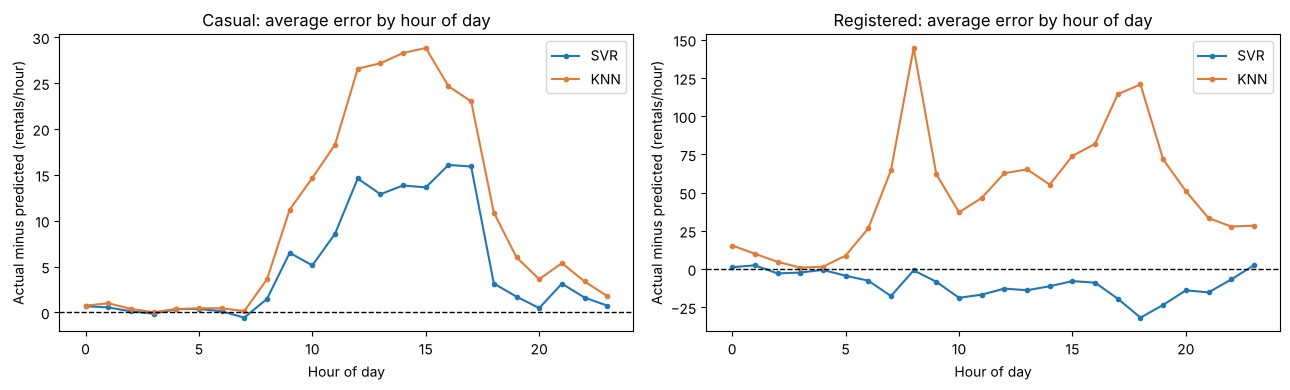

In [8]:
truth = pd.read_csv(ROOT / "data" / "processed" / "test.csv", parse_dates=["datetime"])[["datetime", "hr"]]
preds = pd.read_csv(OUT / "test_predictions.csv", parse_dates=["datetime"]).merge(truth, on="datetime", validate="one_to_one")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, target, title in zip(axes, ["casual", "registered"], ["Casual", "Registered"]):
    for model, color in [("svr", "#1f77b4"), ("knn", "#e07b39")]:
        resid = (preds[target] - preds[f"{model}_{target}"]).groupby(preds.hr).mean()
        ax.plot(resid.index, resid.values, marker="o", ms=3, label=model.upper(), color=color)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"{title}: average error by hour of day", xlabel="Hour of day", ylabel="Actual minus predicted (rentals/hour)")
    ax.legend()
fig.tight_layout()
plt.show()

**What the error-by-hour charts show**
- Both models **under-predict casual rentals during the daytime** (SVR by roughly 15 rentals/hour from midday to late afternoon, KNN by up to about 29). This matches the other teammates' models.
- **KNN under-predicts registered rentals at the rush hours**, by about 145 rentals/hour on average at 8 a.m. and about 120 at 6 p.m. It averages a few similar hours and misses how high those peaks are.
- **SVR's registered errors are small and slightly negative**, meaning it tends to slightly over-predict. Its largest miss is around 6 p.m.

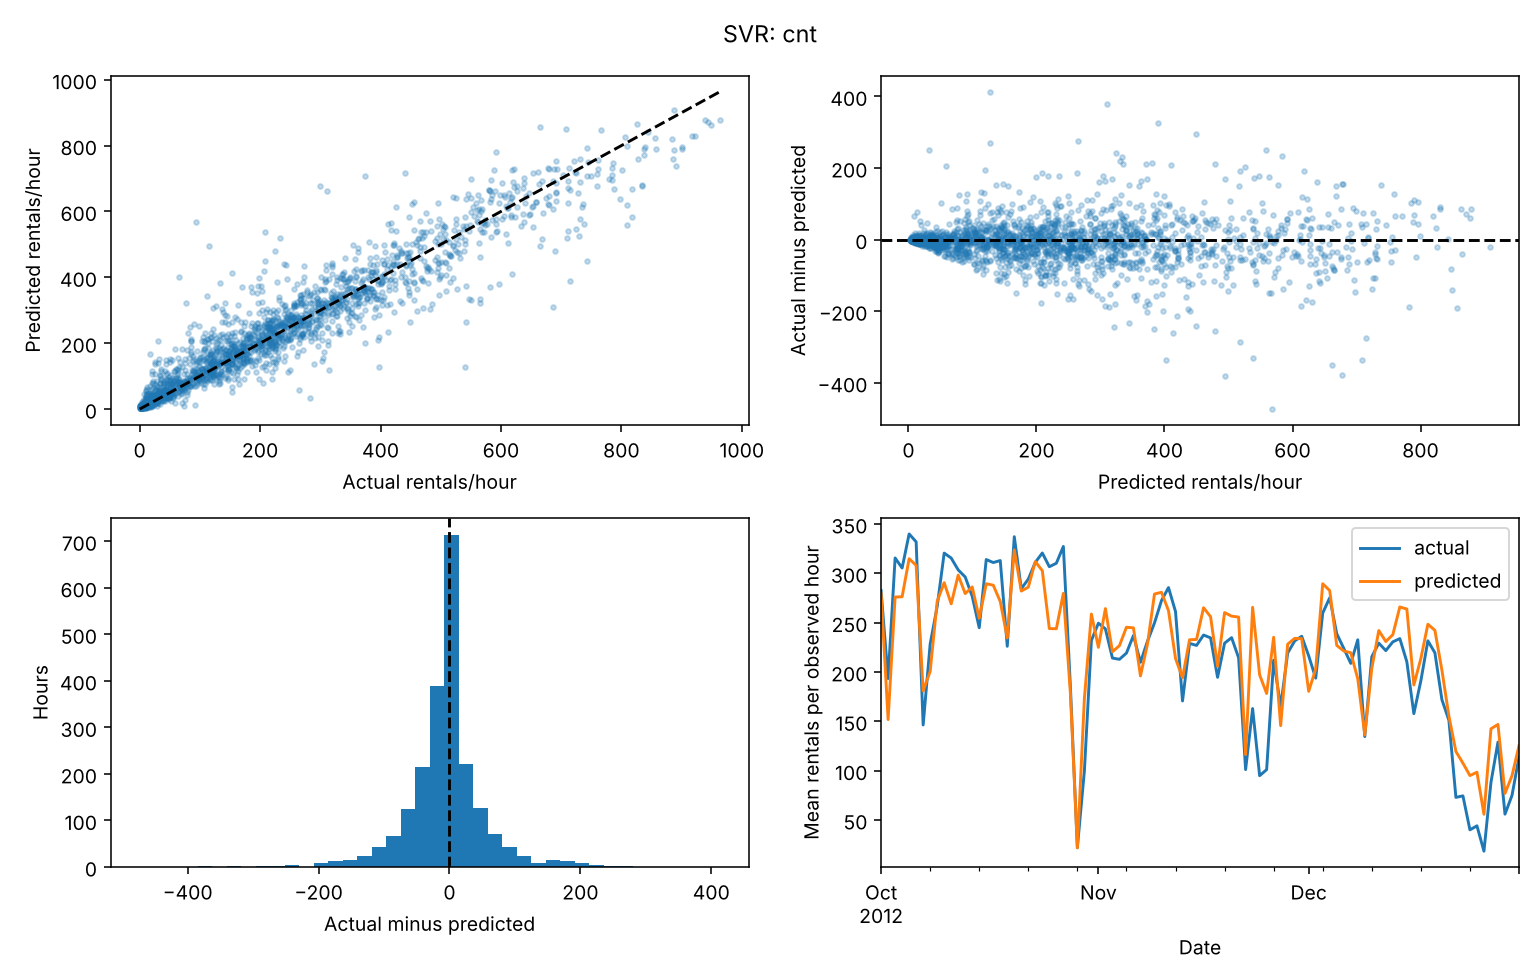

In [9]:
display(Image(filename=str(OUT / "svr_cnt_diagnostics.png"), width=700))

## 6. Summary and limitations

- **SVR was the strongest distance-based model** and had the lowest test error of the saved models for casual, registered and total rentals. **KNN was much weaker**, especially for registered and total demand.
- **Why:** SVR learns smooth patterns across the day and week, while KNN copies a few nearby hours and cannot smooth over the sharp rush-hour peaks.
- **Casual vs registered:** relative to average demand, casual rentals are harder to predict than registered ones. This follows the team's other models.
- **Summing group models:** the effect was tiny and not consistent across models.

**Limitations**
- One three-month test period (October to December 2012), and the team's earlier feature choices also looked at it. These are comparisons on a fixed test set, not untouched estimates.
- Weather is used as observed, and some preprocessing used future weather readings, so this is not a true forecasting test.
- Differences between models are point estimates with no confidence intervals.
- `C=100` was left out of the SVR search because of run time.
